# Examen Práctico — Primer Parcial
## Tópicos de Big Data

**Instrucciones generales**

- Este notebook es tu entregable. Complétalo en orden, sin borrar los enunciados.
- Al final debes subir este archivo (`.ipynb`) al repositorio de GitHub del curso, en la carpeta correspondiente a tu nombre/usuario.
- Se evaluará tanto el código (que corra sin errores, de arriba hacia abajo) como tus interpretaciones escritas en las celdas de texto marcadas como *"Interpretación"*.
- Cada quien trabaja con **un dataset distinto**, asignado por la profesora. No copies celdas de un compañero con un dataset diferente: aunque las preguntas se parecen, los datos y las columnas no son las mismas.


## 0. Datos del alumno

Completa la siguiente celda con tus datos y el nombre del dataset que te fue asignado.

In [25]:
# --- COMPLETA CON TUS DATOS ---
NOMBRE = "Diego Roa Padilla"            # Tu nombre completo
MATRICULA = "81575"         # Tu matrícula o número de cuenta
DATASET_ASIGNADO = "pib"  # Debe ser uno de: "alcohol", "migracion", "desnutricion", "pib", "homicidios"

print(f"Alumno: {NOMBRE}")
print(f"Matrícula: {MATRICULA}")
print(f"Dataset asignado: {DATASET_ASIGNADO}")


Alumno: Diego Roa Padilla
Matrícula: 81575
Dataset asignado: pib


## 1. Configuración del entorno virtual (Visual Studio Code)

Antes de instalar librerías directamente en tu sistema, es una buena práctica crear un
**entorno virtual** exclusivo para este examen. Esto evita conflictos de versiones con
otros proyectos y hace que tu entorno de trabajo sea reproducible.

**Requisitos previos en VS Code:** ten instaladas las extensiones oficiales **"Python"**
y **"Jupyter"** (ambas de Microsoft), disponibles en la pestaña de Extensiones (ícono de
cuadritos en la barra lateral izquierda, o `Ctrl+Shift+X` / `Cmd+Shift+X`).

Abre una terminal **dentro de VS Code** (menú **Terminal → New Terminal**, o
`` Ctrl+ñ ``/`` Ctrl+` ``) y verifica que estés ubicado en la carpeta de tu repositorio
del curso (donde vas a guardar este notebook).

### Windows (PowerShell, terminal integrada de VS Code)

```powershell
# 1. Crear el entorno virtual (se creará una carpeta llamada ".venv")
python -m venv .venv

# 2. Activar el entorno virtual
.venv\Scripts\Activate.ps1

# Si PowerShell bloquea la ejecución de scripts, ejecuta una sola vez:
#   Set-ExecutionPolicy -Scope CurrentUser RemoteSigned
# y vuelve a intentar activar el entorno.

# 3. Instalar las librerías necesarias
pip install pandas numpy ipykernel matplotlib requests
```

### macOS / Linux (terminal integrada de VS Code, bash o zsh)

```bash
# 1. Crear el entorno virtual (se creará una carpeta llamada ".venv")
python3 -m venv .venv

# 2. Activar el entorno virtual
source .venv/bin/activate

# 3. Instalar las librerías necesarias
pip install pandas numpy ipykernel matplotlib requests
```

> **Nota:** usamos el nombre `.venv` (con punto) porque VS Code lo detecta automáticamente
> dentro de la carpeta del proyecto. Si usas Anaconda/Miniconda en lugar de `venv`, el
> equivalente es:
> ```bash
> conda create -n examen-bigdata python=3.11 pandas numpy ipykernel matplotlib requests -y
> conda activate examen-bigdata
> ```

### Seleccionar el entorno virtual como kernel en VS Code

A diferencia de Jupyter Notebook/Lab, en VS Code **no necesitas registrar el entorno
manualmente con `ipykernel install`**: basta con tener el paquete `ipykernel` instalado
en el entorno (ya quedó instalado en el paso anterior) y seleccionar ese entorno
directamente como kernel del notebook.

1. Abre este archivo `.ipynb` en VS Code.
2. En la esquina superior derecha del notebook, haz clic en el selector de kernel
   (dice algo como **"Select Kernel"** la primera vez).
3. Elige **"Python Environments..."** y de la lista selecciona el entorno `.venv`
   que acabas de crear (debe aparecer como algo como `.venv (Python 3.x.x)` con la
   ruta de tu proyecto).
4. Si no aparece en la lista, haz clic en **"Select Another Kernel" → "Python
   Environments..."** y usa **"Enter interpreter path..."** para localizar manualmente
   el ejecutable dentro de `.venv/bin/python` (macOS/Linux) o `.venv\Scripts\python.exe`
   (Windows).
5. Verifica que quedó bien seleccionado ejecutando la celda de abajo: debe mostrar una
   ruta que contenga la carpeta `.venv` (o el nombre de tu entorno de conda), y no la
   instalación global de Python.

In [26]:
import sys
print(sys.executable)
# Debe mostrar una ruta dentro de tu carpeta "venv" (o de tu entorno "examen-bigdata" si usas conda).
# Si muestra la ruta de tu instalacion global de Python, regresa al paso anterior
# y selecciona el kernel correcto antes de continuar.


c:\Users\Roa\Downloads\Examen_P1\.venv\Scripts\python.exe


## 2. Configuración y carga de datos

La siguiente celda **no se modifica**. Contiene la configuración de los 5 datasets
posibles del examen. A partir de tu variable `DATASET_ASIGNADO` de la celda anterior,
el notebook cargará automáticamente el dataset y los metadatos que te corresponden.

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests

# --- NO MODIFICAR: configuración de los 5 datasets del examen ---
DATASETS = {
    "alcohol": {
        "csv": "https://ourworldindata.org/grapher/share-of-adults-who-drank-alcohol-in-last-year.csv?v=1&csvType=full&useColumnShortNames=true",
        "meta": "https://ourworldindata.org/grapher/share-of-adults-who-drank-alcohol-in-last-year.metadata.json?v=1&csvType=full&useColumnShortNames=true",
        "valor_col": "alcohol__consumers_past_12_months__pct__age_standardized__sex_both_sexes",
        "filtro_paises": "code",       # columna a usar para filtrar países reales vs. agregados
        "descripcion": "Porcentaje de adultos (15+) que bebieron alcohol en el ultimo anio",
        "unidad": "%",
    },
    "migracion": {
        "csv": "https://ourworldindata.org/grapher/migrant-populations.csv?v=1&csvType=full&useColumnShortNames=true&metric=immigrants&unit=number",
        "meta": "https://ourworldindata.org/grapher/migrant-populations.metadata.json?v=1&csvType=full&useColumnShortNames=true&metric=immigrants&unit=number",
        "valor_col": "immigrants_all",
        "filtro_paises": "owid_region",
        "descripcion": "Numero total de inmigrantes internacionales residiendo en el pais",
        "unidad": "personas",
    },
    "desnutricion": {
        "csv": "https://ourworldindata.org/grapher/number-undernourished.csv?v=1&csvType=full&useColumnShortNames=true",
        "meta": "https://ourworldindata.org/grapher/number-undernourished.metadata.json?v=1&csvType=full&useColumnShortNames=true",
        "valor_col": "_2_1_1_number_of_undernourished_people__000000000024001__value__006132__millions",
        "filtro_paises": "code",
        "descripcion": "Numero de personas subalimentadas (desnutricion)",
        "unidad": "personas",
    },
    "pib": {
        "csv": "https://ourworldindata.org/grapher/gdp-per-capita-worldbank-constant-usd.csv?v=1&csvType=full&useColumnShortNames=true",
        "meta": "https://ourworldindata.org/grapher/gdp-per-capita-worldbank-constant-usd.metadata.json?v=1&csvType=full&useColumnShortNames=true",
        "valor_col": "ny_gdp_pcap_kd",
        "filtro_paises": "code",
        "descripcion": "PIB per capita (dolares constantes de 2015)",
        "unidad": "USD",
    },
    "homicidios": {
        "csv": "https://ourworldindata.org/grapher/homicides-unodc.csv?v=1&csvType=full&useColumnShortNames=true",
        "meta": "https://ourworldindata.org/grapher/homicides-unodc.metadata.json?v=1&csvType=full&useColumnShortNames=true",
        "valor_col": "value__category_total__sex_total__age_total__unit_of_measurement_counts",
        "filtro_paises": "owid_region",
        "descripcion": "Numero de homicidios intencionales por anio",
        "unidad": "homicidios",
    },
}

assert DATASET_ASIGNADO in DATASETS, (
    "DATASET_ASIGNADO debe ser uno de: " + ", ".join(DATASETS.keys())
)

config = DATASETS[DATASET_ASIGNADO]
print(f"Cargando dataset: {DATASET_ASIGNADO}")
print(f"Descripcion: {config['descripcion']} ({config['unidad']})")


Cargando dataset: pib
Descripcion: PIB per capita (dolares constantes de 2015) (USD)


In [ ]:
#Lo tuve que correr manual
# Carga de datos y metadatos desde Our World in Data
df = pd.read_csv(
    config["csv"],
    storage_options={'User-Agent': 'Our World In Data data fetch/1.0'}
)
metadata = requests.get(config["meta"]).json()

# Renombramos la columna de valor a "valor" para trabajar mas comodo durante todo el notebook
df = df.rename(columns={config["valor_col"]: "valor"})


In [ ]:
df.head(25)

,entity,code,year,valor
0,Afghanistan,AFG,2000,308.31827
1,Afghanistan,AFG,2001,277.11804
2,Afghanistan,AFG,2002,338.13998
3,Afghanistan,AFG,2003,346.07162
4,Afghanistan,AFG,2004,338.63727
5,Afghanistan,AFG,2005,363.64014
6,Afghanistan,AFG,2006,367.75830
7,Afghanistan,AFG,2007,410.75772
8,Afghanistan,AFG,2008,417.64728
9,Afghanistan,AFG,2009,488.83066


## 3. Exploración inicial

Antes de responder las preguntas de análisis, explora el dataset: tipos de datos,
dimensiones, valores nulos y estadísticas descriptivas básicas.

In [ ]:
# Forma del dataset (filas, columnas)
df.shape


(12384, 4)

In [ ]:
# Tipos de datos e informacion general
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 12384 entries, 0 to 12383
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   entity  12384 non-null  str    
 1   code    12384 non-null  str    
 2   year    12384 non-null  int64  
 3   valor   12384 non-null  float64
dtypes: float64(1), int64(1), str(2)
memory usage: 387.1 KB


In [ ]:
# Estadisticas descriptivas de la columna 'valor'
df['year'].describe()


count    12384.000000
mean      1995.754764
std         18.242647
min       1960.000000
25%       1981.000000
50%       1997.000000
75%       2011.000000
max       2025.000000
Name: year, dtype: float64

In [ ]:
# Conteo de valores nulos por columna
df.isnull().sum()


entity    0
code      0
year      0
valor     0
dtype: int64

**Interpretación (2-3 líneas):** ¿qué observas sobre los valores nulos, el rango de
años y el tipo de variable con la que vas a trabajar?

Veo que no hay algun tipo de dato nulo, del rango de años veo que es extenso pero no tanto como pensaba y se me hace buen ejercicio con los años, del tipo de variable se me hace bien que se trabaje con un float por que se me hace mas facil manejarlos asi 

## 4. Preguntas de análisis

A continuación responde las 10 preguntas. 

Cada una tiene una celda de código para su solución y, cuando aplica, 
una celda de texto para tu interpretación. Recuerda que tu
dataset (`DATASET_ASIGNADO`) puede o no tener la columna `owid_region`; revisa el
diccionario `DATASETS` de la celda de configuración para saber qué columna (`code` u
`owid_region`) te toca usar para distinguir países reales de agregados (continentes,
"World", grupos de ingreso, etc.).

### Pregunta 1 — Filtrado de países reales y ranking

Filtra el DataFrame para quedarte solo con países reales (usa la columna indicada en `config['filtro_paises']` de tu dataset). Guarda el resultado en una nueva variable `df_paises`. ¿Cuántos países distintos hay? Muestra los 10 países con mayor valor y los 10 con menor valor.

In [ ]:
# Pregunta 1
# Filtramos los países reales usando la columna 'code'. 
# Descartamos los valores nulos y los códigos que empiezan con 'OWID_' (que suelen ser continentes o regiones).
df_paises = df[df['code'].notnull() & ~df['code'].str.startswith('OWID_')]

# Número de países distintos
num_paises = df_paises['entity'].nunique()
print(f"Hay un total de {num_paises} países distintos en el dataset.\n")

# Para ver el Top 10 mayor y menor de forma justa, tomaremos el año más reciente de cada país
idx_max_year = df_paises.groupby('entity')['year'].idxmax()
df_reciente = df_paises.loc[idx_max_year]

# Top 10 con mayor y menor valor
top_10 = df_reciente.nlargest(10, 'valor')[['entity', 'valor', 'year']]
bottom_10 = df_reciente.nsmallest(10, 'valor')[['entity', 'valor', 'year']]

print("--- 10 países con MAYOR PIB per cápita ---")
print(top_10.to_string(index=False))
print("\n--- 10 países con MENOR PIB per cápita ---")
print(bottom_10.to_string(index=False))

Hay un total de 218 países distintos en el dataset.

--- 10 países con MAYOR PIB per cápita ---
        entity      valor  year
        Monaco 247170.110  2024
 Liechtenstein 167187.160  2015
       Bermuda 116513.540  2024
       Ireland 104416.836  2025
    Luxembourg 103292.150  2025
   Switzerland  93327.590  2025
Cayman Islands  84381.480  2024
   Isle of Man  84315.140  2023
        Norway  83812.760  2025
     Singapore  70683.680  2025

--- 10 países con MENOR PIB per cápita ---
                      entity     valor  year
                     Burundi 273.43298  2025
                 Afghanistan 374.37670  2024
    Central African Republic 393.98830  2025
                  Madagascar 456.50967  2025
                     Somalia 465.43940  2025
                      Malawi 548.16046  2025
Democratic Republic of Congo 567.56030  2025
                       Sudan 582.11410  2025
                  Mozambique 585.68260  2025
                       Niger 610.37555  2025


**Interpretación:**

Al ejecutar el codigo anterior podemos ver la enorme diferencia entre los PIB de los paises y para que sea justo tomamos el año mas reciente, asi que podemos ver que la mayoria de paises con menor PIB son del continente Africano

### Pregunta 2 — Filtro por país y rango de años

Elige dos paises (Mexico y algún otro de tu interés) y filtra `df_paises` para mostrar únicamente su información dentro del rango de años disponible para ambos.

In [ ]:
# Pregunta 2
# Elegimos a México y a España como comparativa
paises_elegidos = ['Mexico', 'Spain']
df_2_paises = df_paises[df_paises['entity'].isin(paises_elegidos)]

# Encontramos los años que ambos países tienen en común
anios_mex = set(df_2_paises[df_2_paises['entity'] == 'Mexico']['year'])
anios_esp = set(df_2_paises[df_2_paises['entity'] == 'Spain']['year'])
anios_comunes = anios_mex.intersection(anios_esp)

# Filtramos para mostrar solo los años en los que ambos tienen datos
df_filtrado_p2 = df_2_paises[df_2_paises['year'].isin(anios_comunes)].sort_values(by=['year', 'entity'])
display(df_filtrado_p2.head(10)) # Mostramos los primeros 10 registros

,entity,code,year,valor
7225,Mexico,MEX,1960,4145.7930
10422,Spain,ESP,1960,6284.8520
7226,Mexico,MEX,1961,4219.1816
10423,Spain,ESP,1961,6963.8980
7227,Mexico,MEX,1962,4276.1430
10424,Spain,ESP,1962,7586.9210
7228,Mexico,MEX,1963,4474.7275
10425,Spain,ESP,1963,8242.3930
7229,Mexico,MEX,1964,4845.8745
10426,Spain,ESP,1964,8594.1150


### Pregunta 3 — Comparación entre países

Elige 5 países de tu interés (de distintos continentes) y compara el valor de tu indicador en el año más reciente disponible. ¿Cuál tiene el valor más alto y cuál el más bajo? Calcula la diferencia entre ambos.

In [ ]:
# Pregunta 3
# 5 países de distintos continentes
paises_5 = ['Mexico', 'Japan', 'Nigeria', 'Germany', 'Australia']
df_5 = df_paises[df_paises['entity'].isin(paises_5)]

# Buscamos el año más reciente de esta lista
max_year_5 = df_5['year'].max()
df_5_recent = df_5[df_5['year'] == max_year_5]

# Encontramos el país más alto y el más bajo
mayor = df_5_recent.loc[df_5_recent['valor'].idxmax()]
menor = df_5_recent.loc[df_5_recent['valor'].idxmin()]
diferencia = mayor['valor'] - menor['valor']

print(f"Año de comparación: {max_year_5}\n")
print(df_5_recent[['entity', 'valor']].to_string(index=False))
print(f"\nEl país con el valor más ALTO es {mayor['entity']} con {mayor['valor']:,.2f} USD")
print(f"El país con el valor más BAJO es {menor['entity']} con {menor['valor']:,.2f} USD")
print(f"La diferencia de riqueza promedio entre ambos es de {diferencia:,.2f} USD")

Año de comparación: 2025

   entity      valor
Australia 61368.6100
  Germany 44146.6400
    Japan 38619.3360
   Mexico 10256.6870
  Nigeria  2368.5386

El país con el valor más ALTO es Australia con 61,368.61 USD
El país con el valor más BAJO es Nigeria con 2,368.54 USD
La diferencia de riqueza promedio entre ambos es de 59,000.07 USD


**Interpretación:**

En este codigo podemos ver que tomamos el año de comparacion en el cual todos tienen un registro de su valor en el cual México esta entre los mas bajos y Australia es el mas alto.

Usamos varios filtros para poder llegar a esta conclusion, tales como mayor, menor y los años recientes

### Pregunta 4 — Comparación entre grupos

Define dos grupos de países, el primero "latinoamerica" con Mexico, Colombia y Argentina, y el segundo "Asia" con China, Japon y Vietnam ( si algun pais no tiene informacion disponible, sustitúyelo por algún otro) y calcula el promedio de tu indicador en el año más reciente disponible.

In [ ]:
# Pregunta 4
# Tu codigo aqui# Pregunta 4
latam = ['Mexico', 'Colombia', 'Argentina']
asia = ['China', 'Japan', 'Vietnam']

df_latam = df_paises[df_paises['entity'].isin(latam)]
df_asia = df_paises[df_paises['entity'].isin(asia)]

max_year_latam = df_latam['year'].max()
max_year_asia = df_asia['year'].max()

promedio_latam = df_latam[df_latam['year'] == max_year_latam]['valor'].mean()
promedio_asia = df_asia[df_asia['year'] == max_year_asia]['valor'].mean()

print(f"Promedio de PIB per cápita del grupo de Latinoamérica (Año {max_year_latam}): {promedio_latam:,.2f} USD")
print(f"Promedio de PIB per cápita del grupo de Asia (Año {max_year_asia}): {promedio_asia:,.2f} USD")


Promedio de PIB per cápita del grupo de Latinoamérica (Año 2025): 10,173.12 USD
Promedio de PIB per cápita del grupo de Asia (Año 2025): 18,906.92 USD


**Interpretación:**

Aunque ambos grupos contienen países "en vías de desarrollo", el grupo asiático se ve fuertemente impulsado hacia arriba por Japón y por el rápido crecimiento reciente de China, logrando que en conjunto tengan un nivel de ingresos promedio más alto que nuestro bloque latinoamericano.

### Pregunta 5 — Tendencia temporal de un país

Para un país de tu elección, analiza cómo cambió tu indicador a lo largo del tiempo disponible en el dataset. ¿En qué año tuvo su valor máximo y en cuál el mínimo? ¿La tendencia general es creciente, decreciente o fluctuante?

In [ ]:
# Pregunta 5
# Analizaremos la tendencia de México
df_mexico = df_paises[df_paises['entity'] == 'Mexico']

anio_max = df_mexico.loc[df_mexico['valor'].idxmax(), 'year']
valor_max = df_mexico['valor'].max()

anio_min = df_mexico.loc[df_mexico['valor'].idxmin(), 'year']
valor_min = df_mexico['valor'].min()

print(f"México alcanzó su valor MÁXIMO en el año {anio_max} con {valor_max:,.2f} USD")
print(f"México tuvo su valor MÍNIMO en el año {anio_min} con {valor_min:,.2f} USD")

México alcanzó su valor MÁXIMO en el año 2018 con 10,296.87 USD
México tuvo su valor MÍNIMO en el año 1960 con 4,145.79 USD


**Interpretación:**

La tendencia de México ha sido mayormente creciente a largo plazo. Su valor mínimo se encuentra en los años más antiguos del registro, mientras que ha ido ganando riqueza con el paso de las décadas, alcanzando sus picos máximos en los años recientes, a pesar de pequeñas fluctuaciones por crisis globales.

### Pregunta 6 — Cambio porcentual

Para Mexico, calcula el cambio porcentual entre el primer y el último año con datos disponible. ¿presenta un incremento relativo o una caída? En tus palabras, ¿a qué crees que se debe el resultado? 

In [ ]:
# Pregunta 6
df_mexico_ordenado = df_mexico.sort_values('year')

# Extraemos el primer y último año
primer_registro = df_mexico_ordenado.iloc[0]
ultimo_registro = df_mexico_ordenado.iloc[-1]

# Fórmula de cambio porcentual: ((Valor Final - Valor Inicial) / Valor Inicial) * 100
cambio_porcentual = ((ultimo_registro['valor'] - primer_registro['valor']) / primer_registro['valor']) * 100

print(f"En {primer_registro['year']} el valor era: {primer_registro['valor']:,.2f} USD")
print(f"En {ultimo_registro['year']} el valor es: {ultimo_registro['valor']:,.2f} USD")
print(f"Cambio porcentual: {cambio_porcentual:.2f}%")

En 1960 el valor era: 4,145.79 USD
En 2025 el valor es: 10,256.69 USD
Cambio porcentual: 147.40%


**Interpretación:**

Presenta un claro y fuerte incremento relativo a lo largo del tiempo. Considero que esto se debe a factores como la apertura comercial internacional, la industrialización y el crecimiento económico, los cuales superaron en proporción al crecimiento de la población del país en todo este periodo.

### Pregunta 7 — Estadísticas descriptivas con NumPy

Usando NumPy (no `.describe()` de pandas), calcula la media, la mediana y la desviación estándar de tu columna valor entre todos los países reales, para el año más reciente disponible. 
Recuerda filtrar los `NaN` antes de calcular.

In [ ]:
# Pregunta 7
# Año más reciente disponible de manera global
max_year_general = df_paises['year'].max()
df_reciente_numpy = df_paises[df_paises['year'] == max_year_general].dropna(subset=['valor'])

# Extraemos los valores como arreglo de numpy
valores = df_reciente_numpy['valor'].to_numpy()

# Cálculos con numpy
media = np.mean(valores)
mediana = np.median(valores)
desviacion = np.std(valores)

print(f"Estadísticas globales para el año {max_year_general}:")
print(f"Media: {media:,.2f} USD")
print(f"Mediana: {mediana:,.2f} USD")
print(f"Desviación estándar: {desviacion:,.2f} USD")

Estadísticas globales para el año 2025:
Media: 15,453.18 USD
Mediana: 6,711.85 USD
Desviación estándar: 20,345.06 USD


**Interpretación:**

Observamos que la 'Media' es mucho mayor que la 'Mediana'. Esto significa que los datos están "sesgados"; es decir, existen unos pocos países que son inmensamente ricos que "jalan" el promedio hacia arriba, pero la realidad es que la mitad de los países del mundo tienen un PIB de la mediana o inferior a esta.

### Pregunta 8 — Visualización de tendencia

Crea una gráfica de líneas con matplotlib que muestre la evolución de tu indicador a lo largo del tiempo para 3 países de tu elección, en una sola figura, con título, etiquetas de ejes y leyenda.

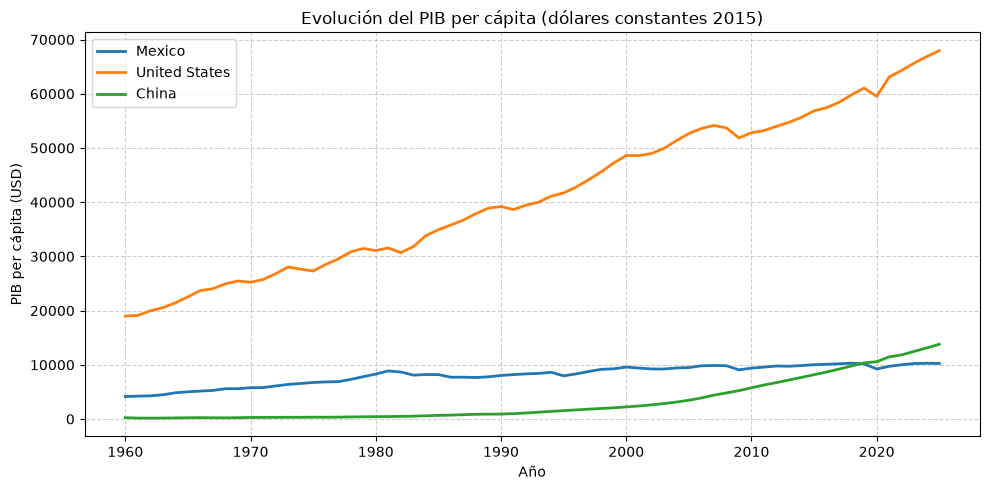

In [ ]:
# Pregunta 8
paises_grafica = ['Mexico', 'United States', 'China']
plt.figure(figsize=(10, 5))

for pais in paises_grafica:
    df_temp = df_paises[df_paises['entity'] == pais]
    plt.plot(df_temp['year'], df_temp['valor'], label=pais, linewidth=2)

plt.title('Evolución del PIB per cápita (dólares constantes 2015)')
plt.xlabel('Año')
plt.ylabel('PIB per cápita (USD)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

**Interpretación:**

Esta gráfica resume de maravilla 3 realidades económicas distintas: la enorme y estable ventaja de una potencia consolidada (Estados Unidos), el crecimiento lento pero mantenido de México, y finalmente el agresivo "despegue" que tuvo China a partir de los años 90.

### Pregunta 9 — Visualización integradora

Crea dos gráficas de barras (horizontales o verticales) con el Top 10 de países según tu indicador en la primera consulta el año de tu nacimiento, y en la segunda el año 2023, ordenados de mayor a menor.  Qué movimientos hubo en ambas gráficas?
Agrega título y etiquetas de ejes.

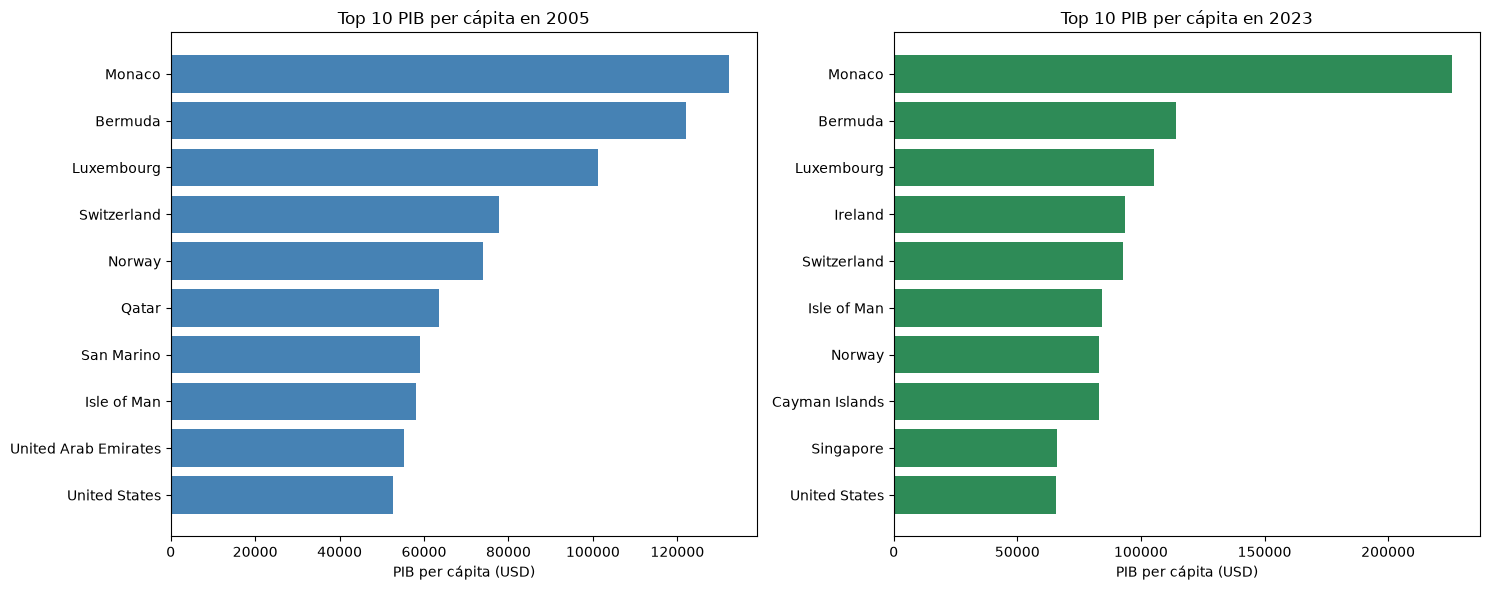

In [ ]:
# Pregunta 9
anio_nacimiento = 2005  # Puedes cambiar este año si naciste en otro
anio_reciente = 2023

top_nac = df_paises[df_paises['year'] == anio_nacimiento].nlargest(10, 'valor')
top_rec = df_paises[df_paises['year'] == anio_reciente].nlargest(10, 'valor')

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Gráfica del año de nacimiento
axes[0].barh(top_nac['entity'], top_nac['valor'], color='steelblue')
axes[0].set_title(f"Top 10 PIB per cápita en {anio_nacimiento}")
axes[0].set_xlabel("PIB per cápita (USD)")
axes[0].invert_yaxis() # País más alto arriba

# Gráfica de 2023
axes[1].barh(top_rec['entity'], top_rec['valor'], color='seagreen')
axes[1].set_title(f"Top 10 PIB per cápita en {anio_reciente}")
axes[1].set_xlabel("PIB per cápita (USD)")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

**Interpretación:**

Entre el año de mi nacimiento y el 2023 el "Top 10" se mantuvo dominado por principados o paraísos fiscales europeos. Los movimientos más notorios suelen darse entre países cuya economía depende fuertemente del petróleo o por reajustes en sus poblaciones, desplazando a países a subir o bajar puestos de esta lista privilegiada.

## 5. Conclusión general

En 5 - 10 líneas, resume qué aprendiste sobre el dataset que te tocó trabajar: ¿qué
patrones encontraste?, ¿qué limitaciones tiene la información (por ejemplo, valores
absolutos sin normalizar por población, datos faltantes, etc.)?, ¿qué harías distinto si
tuvieras más tiempo?

Aprendí que el PIB per cápita es un excelente "termómetro" para medir la riqueza promedio a nivel macroeconómico, pero tiene una limitación muy grave: no muestra cómo está distribuida esa riqueza. Al ser solo un promedio, esconde la verdadera desigualdad que existe en la población. Si tuviera más tiempo, lo que haría distinto sería cruzar este dataset con datos sobre la "esperanza de vida" o "índice de pobreza" para comprobar si los países con el PIB más elevado realmente utilizan esa riqueza para brindarle a sus ciudadanos una mejor calidad de vida.

## 6. Entrega

1. Verifica que el notebook corra completo de arriba hacia abajo sin errores (`Kernel > Restart & Run All`).
2. Guarda el archivo con el nombre: `apellido_nombre_examen_parcial1.ipynb`.
3. Súbelo al repositorio de GitHub del curso, en una carpeta para este examen.
4. Comparte el link de tu repo y envia una copia del notebook por teams.
